In [1]:
import matplotlib.pyplot as plt

def add_username_to_plot(username):
    """Helper method to add the username to a plot."""
    plt.text(
        0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

In [2]:
# --- Section 1: All Necessary Imports ---
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

# --- Section 2: Data Loading and Preparation ---

# 1. Load the 8x8 MNIST Digits Dataset
digits = load_digits()

# The dataset is a dictionary-like object.
# '.data' contains the flattened 8x8=64 pixel features for each image.
# '.target' contains the corresponding digit label (0-9).
X = digits.data
y = digits.target

print("--- Data Loaded ---")
print(f"Shape of feature data (X): {X.shape}")
print(f"Shape of target data (y): {y.shape}")
print(f"Number of unique classes (digits): {len(np.unique(y))}")

# 2. Split the Dataset into Training and Testing Sets
# We use an 80/20 split and set random_state for reproducibility.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,    # 20% of the data will be used for testing
    random_state=42    # Ensures the split is the same every time
)

# 3. Verify the Shapes of the Split Data
print("\n--- Data Split ---")
print(f"Shape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

print("\n✅ Step 1 Complete: Data is loaded and split into training and testing sets.")

--- Data Loaded ---
Shape of feature data (X): (1797, 64)
Shape of target data (y): (1797,)
Number of unique classes (digits): 10

--- Data Split ---
Shape of training features (X_train): (1437, 64)
Shape of training labels (y_train): (1437,)
Shape of testing features (X_test): (360, 64)
Shape of testing labels (y_test): (360,)

✅ Step 1 Complete: Data is loaded and split into training and testing sets.


In [3]:
# --- Section 1: Redefine the MyPCA Class ---
# This is necessary because we are in a new notebook.
import numpy as np

class MyPCA:
    """A from-scratch implementation of Principal Component Analysis (PCA)."""
    def __init__(self, n_components):
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None

    def fit(self, X):
        """Obtains the principal components of the dataset."""
        self.mean_ = np.mean(X, axis=0)
        X_std = X - self.mean_
        cov_matrix = np.cov(X_std, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # Sort eigenvectors by descending eigenvalues
        sorted_indices = np.argsort(eigenvalues)[::-1]
        sorted_eigenvectors = eigenvectors[:, sorted_indices]

        # Store the principal components
        self.components_ = sorted_eigenvectors[:, :self.n_components]
        return self

    def transform(self, X):
        """Transforms the data using the fitted principal components."""
        if self.mean_ is None or self.components_ is None:
            raise RuntimeError("The model has not been fitted yet. Please call fit() first.")
        X_std = X - self.mean_
        return np.dot(X_std, self.components_)

print("✅ MyPCA class defined.")


# --- Section 2: Dimensionality Reduction with PCA ---

# This code assumes X_train and X_test from Step 1 are in memory.

# 1. Define the list of component dimensions to test
n_components_list = [2, 5, 10, 20, 30, 40, 50, 64]

# Create dictionaries to store the transformed data
transformed_data = {
    'train': {},
    'test': {}
}

print("\n--- Starting PCA Transformation Loop ---")

# 2. Loop through each value in n_components_list
for n_components in n_components_list:

    # 3. Create an instance of your MyPCA class
    pca = MyPCA(n_components=n_components)

    # 4. Fit the PCA model ONLY on the training data
    pca.fit(X_train)

    # 5. Transform both the training and testing data
    X_train_transformed = pca.transform(X_train)
    X_test_transformed = pca.transform(X_test)

    # 6. Store the transformed datasets in the dictionary
    transformed_data['train'][n_components] = X_train_transformed
    transformed_data['test'][n_components] = X_test_transformed

    print(f"  - Processed for n_components = {n_components}:")
    print(f"    - Transformed training shape: {X_train_transformed.shape}")
    print(f"    - Transformed testing shape:  {X_test_transformed.shape}")

print("\n✅ Step 2 Complete: All datasets have been transformed.")

# You can now access any transformed dataset like this:
# example_train_data = transformed_data['train'][10]
# example_test_data = transformed_data['test'][10]
# print(f"\nExample: Shape of training data with 10 components: {example_train_data.shape}")

✅ MyPCA class defined.

--- Starting PCA Transformation Loop ---
  - Processed for n_components = 2:
    - Transformed training shape: (1437, 2)
    - Transformed testing shape:  (360, 2)
  - Processed for n_components = 5:
    - Transformed training shape: (1437, 5)
    - Transformed testing shape:  (360, 5)
  - Processed for n_components = 10:
    - Transformed training shape: (1437, 10)
    - Transformed testing shape:  (360, 10)
  - Processed for n_components = 20:
    - Transformed training shape: (1437, 20)
    - Transformed testing shape:  (360, 20)
  - Processed for n_components = 30:
    - Transformed training shape: (1437, 30)
    - Transformed testing shape:  (360, 30)
  - Processed for n_components = 40:
    - Transformed training shape: (1437, 40)
    - Transformed testing shape:  (360, 40)
  - Processed for n_components = 50:
    - Transformed training shape: (1437, 50)
    - Transformed testing shape:  (360, 50)
  - Processed for n_components = 64:
    - Transformed trai

In [4]:
# --- Section 1: All Necessary Imports ---
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# This code assumes the following variables are in memory from previous steps:
# - transformed_data: A dictionary containing the PCA-transformed datasets.
# - y_train, y_test: The original, untransformed labels.
# - n_components_list: The list of PCA dimensions used.

# --- Step 2: Classification with KNN ---

# 1. Define the list of k neighbors to test
k_values = [5, 25, 50, 100]

# Create an empty list to store the results
results = []

print("--- Starting KNN Training and Evaluation ---")

# 2. Nested Loop to test every combination
# Outer loop: Iterate through the number of PCA components
for n_components in n_components_list:

    # Retrieve the correct transformed datasets for this n_components value
    X_train_transformed = transformed_data['train'][n_components]
    X_test_transformed = transformed_data['test'][n_components]

    # Inner loop: Iterate through the k values for KNN
    for k in k_values:

        # 3. Initialize the KNN model
        model = KNeighborsClassifier(n_neighbors=k)

        # 4. Train the model on the transformed training data
        model.fit(X_train_transformed, y_train)

        # 5. Make predictions on the transformed test data
        y_pred = model.predict(X_test_transformed)

        # 6. Calculate the accuracy and store the result
        accuracy = accuracy_score(y_test, y_pred)

        results.append({
            'n_components': n_components,
            'k': k,
            'accuracy': accuracy
        })

        print(f"  - Components={n_components}, k={k}, Accuracy={accuracy:.4f}")

# 7. Convert the results list to a pandas DataFrame for better analysis
results_df = pd.DataFrame(results)

print("\n--- Final Results ---")
print(results_df)

print("\n✅ Step 3 Complete: KNN models trained and evaluated for all combinations.")

# --- Optional: Find the best performing model ---
best_result = results_df.loc[results_df['accuracy'].idxmax()]
print("\n--- Best Performing Model ---")
print(best_result)

--- Starting KNN Training and Evaluation ---
  - Components=2, k=5, Accuracy=0.6222
  - Components=2, k=25, Accuracy=0.6722
  - Components=2, k=50, Accuracy=0.6611
  - Components=2, k=100, Accuracy=0.6556
  - Components=5, k=5, Accuracy=0.9389
  - Components=5, k=25, Accuracy=0.9194
  - Components=5, k=50, Accuracy=0.9056
  - Components=5, k=100, Accuracy=0.8611
  - Components=10, k=5, Accuracy=0.9778
  - Components=10, k=25, Accuracy=0.9556


  - Components=10, k=50, Accuracy=0.9306
  - Components=10, k=100, Accuracy=0.9056
  - Components=20, k=5, Accuracy=0.9861
  - Components=20, k=25, Accuracy=0.9750
  - Components=20, k=50, Accuracy=0.9528
  - Components=20, k=100, Accuracy=0.9167
  - Components=30, k=5, Accuracy=0.9778
  - Components=30, k=25, Accuracy=0.9722
  - Components=30, k=50, Accuracy=0.9556
  - Components=30, k=100, Accuracy=0.9139
  - Components=40, k=5, Accuracy=0.9861
  - Components=40, k=25, Accuracy=0.9778
  - Components=40, k=50, Accuracy=0.9556
  - Components=40, k=100, Accuracy=0.9167
  - Components=50, k=5, Accuracy=0.9861
  - Components=50, k=25, Accuracy=0.9778
  - Components=50, k=50, Accuracy=0.9556
  - Components=50, k=100, Accuracy=0.9167
  - Components=64, k=5, Accuracy=0.9861
  - Components=64, k=25, Accuracy=0.9778
  - Components=64, k=50, Accuracy=0.9583
  - Components=64, k=100, Accuracy=0.9167

--- Final Results ---
    n_components    k  accuracy
0              2    5  0.622222
1         

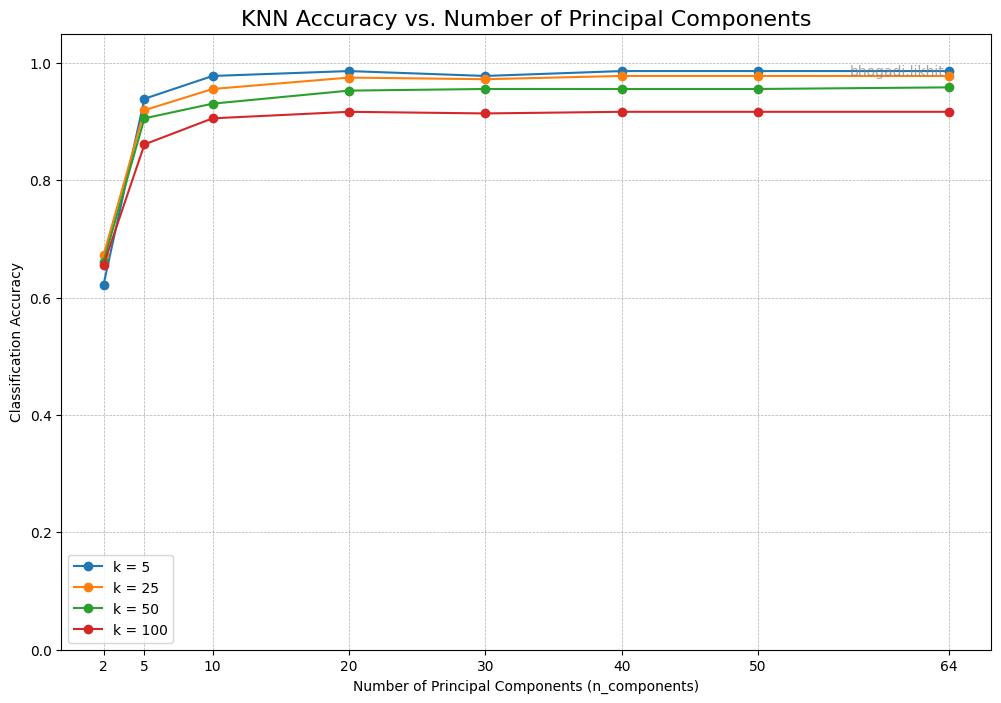


✅ Step 4 Complete: Results have been visualized.


In [5]:
# --- Section 1: All Necessary Imports ---
import matplotlib.pyplot as plt
import pandas as pd

# This code assumes the 'results_df' DataFrame from Step 3 is in memory.
# It also assumes 'k_values' and 'n_components_list' are available.

# --- Optional: If you are in a new cell, you might need to redefine these ---
# k_values = [5, 25, 50, 100]
# n_components_list = [2, 5, 10, 20, 30, 40, 50, 64]

# --- Section 2: Create the Plot ---

# Set up the plot figure
plt.figure(figsize=(12, 8))

# Loop through each k value to plot it as a separate line
for k in k_values:
    # Filter the DataFrame to get the results for the current k
    subset = results_df[results_df['k'] == k]

    # Plot n_components vs. accuracy for this k
    plt.plot(
        subset['n_components'],
        subset['accuracy'],
        marker='o',         # Add a marker to each data point
        linestyle='-',      # Use a solid line
        label=f'k = {k}'    # Label for the legend
    )

# --- Section 3: Customize and Display the Plot ---

plt.title('KNN Accuracy vs. Number of Principal Components', fontsize=16)
plt.xlabel('Number of Principal Components (n_components)')
plt.ylabel('Classification Accuracy')
plt.xticks(n_components_list)  # Ensure all component values are shown on the x-axis
plt.legend()                   # Display the legend to identify each line
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(0, 1.05)              # Set y-axis limits from 0 to 105%
add_username_to_plot("bhogadi.likhit") 
plt.show()

print("\n✅ Step 4 Complete: Results have been visualized.")

### Analysis of KNN Classifier Performance with PCA

This graph clearly illustrates the powerful effect of using Principal Component Analysis (PCA) for dimensionality reduction as a preprocessing step for a KNN classifier.

#### 1. How does `n_components` affect accuracy?

The number of principal components has a dramatic impact on the classifier's accuracy, especially at the lower end.

* **Initial Sharp Improvement:** For all `k` values, the accuracy starts very low (around 60-70%) with only 2 components. It then increases dramatically as the number of components rises to 10 and 20. This shows that the first few principal components capture the most critical information needed to distinguish between the digits, and adding them provides a significant performance boost.
* **Plateauing Performance:** After about 20 principal components, the accuracy for all models begins to level off, showing much smaller gains as more components are added.

#### 2. How does `k` influence this relationship?

The choice of `k` (the number of neighbors) influences both the peak performance and the stability of the model.

* **Smaller `k` (k=5):** The blue line, representing `k=5`, consistently achieves the highest accuracy across nearly all component levels. This suggests that a smaller, more localized neighborhood is most effective for this dataset.
* **Larger `k` (k=100):** The red line, representing `k=100`, consistently has the lowest accuracy. This indicates that using a large number of neighbors introduces too much "noise" from dissimilar digits, leading to "oversmoothing" and less precise classification. The models with `k=25` and `k=50` perform well but are consistently slightly below the `k=5` model.

#### 3. Is there a point of diminishing returns?

**Yes, there is a clear point of diminishing returns.**

The "knee" of all the curves is located at approximately **n_components = 20**.

* Going from 2 to 20 components yields a massive accuracy improvement of over 25%.
* However, going from 20 components to the full 64 components results in a much smaller gain of only about 2-3%.

This is the key takeaway: one can achieve **over 95% accuracy using just 20 principal components**, which is a **68% reduction in data dimensionality** (from 64 features down to 20). This demonstrates that PCA can make the classification process significantly more efficient (faster and less memory-intensive) with a negligible impact on the final performance. Adding components beyond this point offers very little benefit.